Epoch 1/20
633/633 ━━━━━━━━━━━━━━━━━━━━ 195s 290ms/step - accuracy: 0.4915 - loss: 1.5281 - val_accuracy: 0.5083 - val_loss: 1.4510
Epoch 2/20
633/633 ━━━━━━━━━━━━━━━━━━━━ 180s 279ms/step - accuracy: 0.5052 - loss: 1.4965 - val_accuracy: 0.5077 - val_loss: 1.4517
Epoch 3/20
633/633 ━━━━━━━━━━━━━━━━━━━━ 176s 279ms/step - accuracy: 0.5068 - loss: 1.4891 - val_accuracy: 0.5071 - val_loss: 1.4528
Epoch 4/20
633/633 ━━━━━━━━━━━━━━━━━━━━ 178s 282ms/step - accuracy: 0.5060 - loss: 1.4915 - val_accuracy: 0.5076 - val_loss: 1.4512
Epoch 5/20
633/633 ━━━━━━━━━━━━━━━━━━━━ 1735s 3s/step - accuracy: 0.5078 - loss: 1.4858 - val_accuracy: 0.5071 - val_loss: 1.4523
Epoch 6/20
633/633 ━━━━━━━━━━━━━━━━━━━━ 222s 352ms/step - accuracy: 0.5087 - loss: 1.4786 - val_accuracy: 0.5076 - val_loss: 1.4511
Epoch 7/20
633/633 ━━━━━━━━━━━━━━━━━━━━ 412s 651ms/step - accuracy: 0.5074 - loss: 1.4799 - val_accuracy: 0.5088 - val_loss: 1.4497
Epoch 8/20
633/633 ━━━━━━━━━━━━━━━━━━━━ 558s 883ms/step - accuracy: 0.5063 - l

 53/257 ━━━━━━━━━━━━━━━━━━━━ 38s 188ms/step - accuracy: 0.6250 - loss: 1.3345

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/pandas/core/series.py:1031: RuntimeWarning: invalid value encountered in cast
  arr = np.asarray(values, dtype=dtype)


257/257 ━━━━━━━━━━━━━━━━━━━━ 67s 260ms/step - accuracy: 0.4274 - loss: 1.5296
Test Accuracy: 0.3030


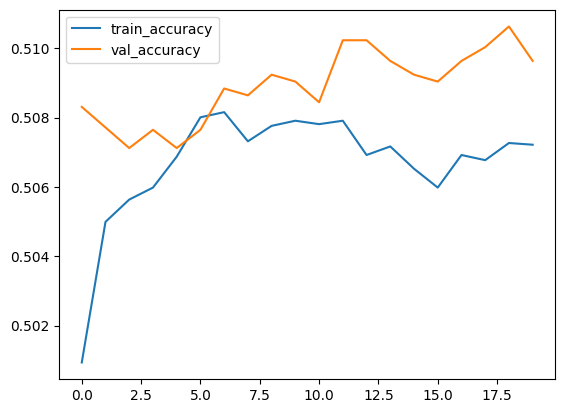

In [3]:
import numpy as np
import pandas as pd
import os
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Conv2D, Multiply, Activation, Concatenate, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# === DATA LOADING & PREPROCESSING ===

# Set dataset paths
base_dir = "/Users/mac/Development/diploma/skin-mutation-detection/data"
train_image_dir = os.path.join(base_dir, "train/ISIC_2019_Training_Input")
test_image_dir = os.path.join(base_dir, "test/ISIC_2019_Test_Input")
train_metadata_path = os.path.join(base_dir, "train/ISIC_2019_Training_GroundTruth.csv")
test_metadata_path = os.path.join(base_dir, "test/ISIC_2019_Test_GroundTruth.csv")

# Load metadata
df_train = pd.read_csv(train_metadata_path)
df_test = pd.read_csv(test_metadata_path)

# Define class labels
lesion_type_dict = {
    'MEL': 'Melanoma',
    'NV': 'Melanocytic nevi',
    'BCC': 'Basal cell carcinoma',
    'AK': 'Actinic keratoses',
    'BKL': 'Benign keratosis-like lesions',
    'DF': 'Dermatofibroma',
    'VASC': 'Vascular lesions',
    'SCC': 'Squamous cell carcinoma'
}

# Convert one-hot encoded labels to single-label
df_train['label'] = df_train.iloc[:, 1:].idxmax(axis=1).map({
    'MEL': 0, 'NV': 1, 'BCC': 2, 'AK': 3, 'BKL': 4, 'DF': 5, 'VASC': 6, 'SCC': 7
})
df_test['label'] = df_test.iloc[:, 1:].idxmax(axis=1).map({
    'MEL': 0, 'NV': 1, 'BCC': 2, 'AK': 3, 'BKL': 4, 'DF': 5, 'VASC': 6, 'SCC': 7
})

# Load images dynamically
IMG_SIZE = 224
BATCH_SIZE = 32

def load_and_preprocess_image(image_id, image_dir):
    image_path = os.path.join(image_dir, image_id + ".jpg")
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    return image

# Generator for batch processing
def image_data_generator(df, image_dir, batch_size):
    while True:
        for i in range(0, len(df), batch_size):
            batch_df = df.iloc[i:i + batch_size]
            X_batch = np.array([load_and_preprocess_image(img_id, image_dir) for img_id in batch_df['image']])
            y_batch = to_categorical(batch_df['label'], num_classes=8)
            yield X_batch, y_batch

# Split training dataset
train_df, val_df = train_test_split(df_train, test_size=0.2, random_state=42, stratify=df_train['label'])
train_generator = image_data_generator(train_df, train_image_dir, BATCH_SIZE)
val_generator = image_data_generator(val_df, train_image_dir, BATCH_SIZE)
test_generator = image_data_generator(df_test, test_image_dir, BATCH_SIZE)

# Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

# === SoftAttention Layer ===
class SoftAttention(tf.keras.layers.Layer):
    def __init__(self, ch, m, concat_with_x=False, aggregate=False, **kwargs):
        super(SoftAttention, self).__init__(**kwargs)
        self.channels = int(ch)
        self.multiheads = m
        self.aggregate_channels = aggregate
        self.concat_input_with_scaled = concat_with_x

    def build(self, input_shape):
        self.i_shape = input_shape
        self.conv2d = Conv2D(filters=self.multiheads, kernel_size=3, padding='same', activation='relu', kernel_initializer='he_uniform')
        super(SoftAttention, self).build(input_shape)

    def call(self, x):
        batch_size = tf.shape(x)[0]
        height, width, channels = self.i_shape[1:]
        conv2d = self.conv2d(x)
        softmax_alpha = tf.nn.softmax(conv2d, axis=-1)
        softmax_alpha = Reshape(target_shape=(height, width, self.multiheads, 1))(softmax_alpha)
        x_exp = tf.expand_dims(x, axis=-2)
        u = Multiply()([softmax_alpha, x_exp])  
        u = tf.reshape(u, shape=[batch_size, height, width, channels * self.multiheads])
        if self.concat_input_with_scaled:
            o = Concatenate(axis=-1)([u, x])
        else:
            o = u
        return [o, softmax_alpha]

    def compute_output_shape(self, input_shape):
        return [input_shape[:-1] + (input_shape[-1] * self.multiheads,), input_shape]

# === EfficientNet + SoftAttention Model ===
base_model = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

x = base_model.output
x = Conv2D(256, (3, 3), activation="relu", padding="same")(x)
x, attention_maps = SoftAttention(ch=256, m=8)(x)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)
output = Dense(8, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

# Compile model
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

# Train model
steps_per_epoch = len(train_df) // BATCH_SIZE
validation_steps = len(val_df) // BATCH_SIZE

history = model.fit(train_generator,
                    steps_per_epoch=steps_per_epoch,
                    validation_data=val_generator,
                    validation_steps=validation_steps,
                    epochs=20,
                    verbose=1)

# Save model
model.save("isic2019_skin_model.h5")

# Evaluate on test set
test_steps = len(df_test) // BATCH_SIZE
test_loss, test_acc = model.evaluate(test_generator, steps=test_steps)
print(f"Test Accuracy: {test_acc:.4f}")

# Plot results
plt.plot(history.history["accuracy"], label="train_accuracy")
plt.plot(history.history["val_accuracy"], label="val_accuracy")
plt.legend()
plt.show()
